# Análisis Avanzado de Datos & Modelado
**Institución:** Universidad Católica Boliviana "San Pablo"  
**Programa:** Maestría en Ciencia de Datos  
**Autor:** Carlos Andrés Pérez Guzmán  
**Fecha:** Agosto 2026  

---
**Entorno y Objetivos del Notebook**
> **Nota:** Este cuaderno implementa una prueba de concepto para el proyecto de segunda fase en la Maestría en Ciencia de Datos.

* **Fase del Proyecto:** Prueba de concepto
* **Core Tech Stack:** `Python` (Programación general para ciencia de datos)
---

<h3 style="color:#05856d">1. Librerías</h3>
<hr>

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import polars as pl
import polars.selectors as cs
import seaborn as sns
from matplotlib import ticker

<h3 style="color:#05856d">2. Carga y limpieza de información</h3>
<hr>

Se importan las funciones de carga y limpieza de datos

In [2]:
from s_01_functions import limpiar_texto_own, load_data_own

df = (
    load_data_own( file_path_param = 'iowa_liquor_sales_2026_1263_rows.csv')
    .with_columns( limpiar_texto_own(column_param = cs.string() - cs.by_name('ordered_on')),
                   pl.col('ordered_on').str.to_date(format = '%Y-%m-%d') )
    .with_columns( pl.col('im_desc','category_name').cast(dtype = pl.Categorical()),
                   pl.col('sales_bottles').cast(dtype = pl.Int64()) ) )

df.glimpse()

Iniciando carga de datos locales desde: iowa_liquor_sales_2026_1263_rows.csv
Carga completada: 964947 registros en 0.33 segundos.
Rows: 964947
Columns: 21
$ bottle_volume_ml  <f64> 750.0, 1750.0, 375.0, 50.0, 1750.0, 375.0, 375.0, 750.0, 750.0, 50.0
$ category_code     <i64> 1011100, 1012100, 1012100, 1012100, 1062400, 1062400, 1011200, 1011200, 1011200, 1011200
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ county_fips_code  <i64> 19177, 19177, 19177, 19177, 19177, 19177, 19177, 19177, 19177, 19177
$ county_name       <str> 'VAN BUREN', 'VAN BUREN', 'VAN BUREN', 'VAN BUREN', 'VAN BUREN', 'VAN BUREN', 'VAN BUREN', 'VAN BUREN', 'VAN BUREN', 'VAN BUREN'
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JI

<h3 style="color:#05856d">3. Selección de variables y transformaciones particulares</h3>
<hr>

Es importante identificar qué variables tienen alguna funcionalidad estratégica al construir un modelo de decisión.

Se elimina la categoría del porducto debido a que no es consistente con el número de producto (item_no)

In [3]:
# Variables con utilidad estratégica
df_selected_variables = [ 'ordered_on','item_no','im_desc','sales_bottles',
                          'category_name','sales_dollars','pack','bottle_volume_ml' ]

# Variables sin utilidad estratégica
df_eliminated_variables = set(df.columns) - set(df_selected_variables)
print('Variables sin utilidad estratégica:', *sorted(df_eliminated_variables), '\n', sep = '\n')

# Selección de variables de interés
df_01 = df.select(df_selected_variables)
df_01.glimpse()

Variables sin utilidad estratégica:
category_code
county_fips_code
county_name
invoice_id
sales_gallons
sales_liters
store_address
store_city
store_name
store_no
store_zip_code
vendor_name
vendor_number


Rows: 964947
Columns: 8
$ ordered_on       <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ item_no           <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ sales_bottles     <i64> 2, 6, 7, 2, 12, 8, 7, 2, 2, 2
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ sales_dollars     <f64> 34.5, 103.5, 34.16, 

Revisar integridad de la llave del producto

In [4]:
duplicados_im_desc = (
    df_01
    .select('item_no', 'im_desc')
    .unique()
    .filter(pl.col('im_desc').is_duplicated())
    .sort('im_desc','item_no')
)

print(f"Duplicados por la descripción del producto (im_desc): {duplicados_im_desc.height > 0}. Casos: {duplicados_im_desc.height}")
print(duplicados_im_desc.head())

duplicados_item_no = (
    df_01
    .select('item_no', 'im_desc')
    .unique()
    .filter(pl.col('item_no').is_duplicated())
    .sort('item_no','im_desc')
)

print(f"Duplicados por número de ítem (item_no): {duplicados_item_no.height > 0}. Casos: {duplicados_item_no.height}")
print(duplicados_item_no.head())


aux = df_01.select('item_no','im_desc').unique().is_duplicated().any()
print(f"\nDuplicados por la descripción del producto (im_desc) y número de item (item_no): {aux}")


Duplicados por la descripción del producto (im_desc): True. Casos: 1072
shape: (5, 2)
┌─────────┬──────────────────────────┐
│ item_no ┆ im_desc                  │
│ ---     ┆ ---                      │
│ i64     ┆ cat                      │
╞═════════╪══════════════════════════╡
│ 21235   ┆ 1792 SMALL BATCH BOURBON │
│ 21239   ┆ 1792 SMALL BATCH BOURBON │
│ 64933   ┆ 1800 COCONUT             │
│ 964931  ┆ 1800 COCONUT             │
│ 89206   ┆ 1800 REPOSADO            │
└─────────┴──────────────────────────┘
Duplicados por número de ítem (item_no): True. Casos: 58
shape: (5, 2)
┌─────────┬─────────────────────────────────┐
│ item_no ┆ im_desc                         │
│ ---     ┆ ---                             │
│ i64     ┆ cat                             │
╞═════════╪═════════════════════════════════╡
│ 1799    ┆ CAPTAIN MORGAN ORIGINAL SPICED… │
│ 1799    ┆ CAPTAIN MORGAN ORIGINAL SPICED… │
│ 7224    ┆ MACALLAN SHERRY OAK 12YO 110 P… │
│ 7224    ┆ MACALLAN SHERRY OAK 12YO 110PF  │


Dado que existe unicidad combinando im_desc e item_no, se creará una nueva variable para reducir la dimensionalidad del dataframe.

In [5]:
df_01 = (
    df_01
    .with_columns(
        pl.format(
            'PRD_{}',
            pl.concat_str( [pl.col('item_no').cast(pl.String), pl.col('im_desc')], separator = '_' )
            .rank(method = 'dense')
            .cast(pl.String)
            .str.zfill(6) ).alias('product_code'))
    .pipe(lambda df: df.select(sorted(df.columns))) )

df_01.glimpse()

Rows: 964947
Columns: 9
$ bottle_volume_ml  <f64> 750.0, 1750.0, 375.0, 50.0, 1750.0, 375.0, 375.0, 750.0, 750.0, 50.0
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ item_no           <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on       <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ pack              <i64> 12, 6, 24, 10, 6, 24, 24, 12, 12, 12
$ product_code      <str> 'PRD_000917', 'PRD_000180', 'PRD_000176', 'PRD_000156', 'PRD_001524', 'PRD_001520', 'PRD_000487', 'PRD_000935', 'PRD_000906

<h3 style="color:#05856d">4. Análisis exploratorio</h3>
<hr>

¿Qué ventas son relevantes?

In [6]:
analysis_01 = (
    df_01
    .group_by(['product_code'])
    .agg(

        # 1. ¿Qué productos están involucrado?
        pl.col('category_name').unique().str.join(', '),

        # 2. ¿Cuántas botellas se han vendido en la historia de este producto?
        pl.sum('sales_bottles').alias('volumen_total'),

        # 3. Ingresos genereados por la venta de botellas (expresado en miles)
        (pl.sum('sales_dollars')/1e3).alias('sales_miles'),
        
        # 3. ¿En cuántos días únicos alguien compró al menos 1 botella?
        pl.n_unique('ordered_on').alias('frecuencia_dias_demanda'),
        pl.n_unique('ordered_on').cut(
            breaks = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
            labels = [
                '0-10 días', '10-20 días', '20-30 días', '30-40 días', '40-50 días', 
                '50-60 días', '60-70 días', '70-80 días', '80-90 días', 
                '90-100 días', '>100 días'],
            left_closed = False ).alias('frecuencia_dias_demanda_cat') )
    
    # Ordenamos por los que tienen demanda más constante, y luego por volumen
    .sort(['frecuencia_dias_demanda', 'sales_miles'], descending = [True, True])
)

print(f"Existen {df_01.n_unique(subset = ['product_code'])} productos únicos en el dataset.")
print(analysis_01.shape)
analysis_01.head()

Existen 4048 productos únicos en el dataset.
(4048, 6)


product_code,category_name,volumen_total,sales_miles,frecuencia_dias_demanda,frecuencia_dias_demanda_cat
str,str,i64,f64,u32,enum
"""PRD_001343""","""AMERICAN VODKAS""",195662,3866.0734,115,""">100 días"""
"""PRD_000180""","""CANADIAN WHISKIES""",159974,2758.791,115,""">100 días"""
"""PRD_001240""","""AMERICAN VODKAS""",252071,695.18428,115,""">100 días"""
"""PRD_001699""","""IMPORTED BRANDIES""",35671,614.49104,115,""">100 días"""
"""PRD_001127""","""IMPORTED VODKAS""",11455,194.735,115,""">100 días"""


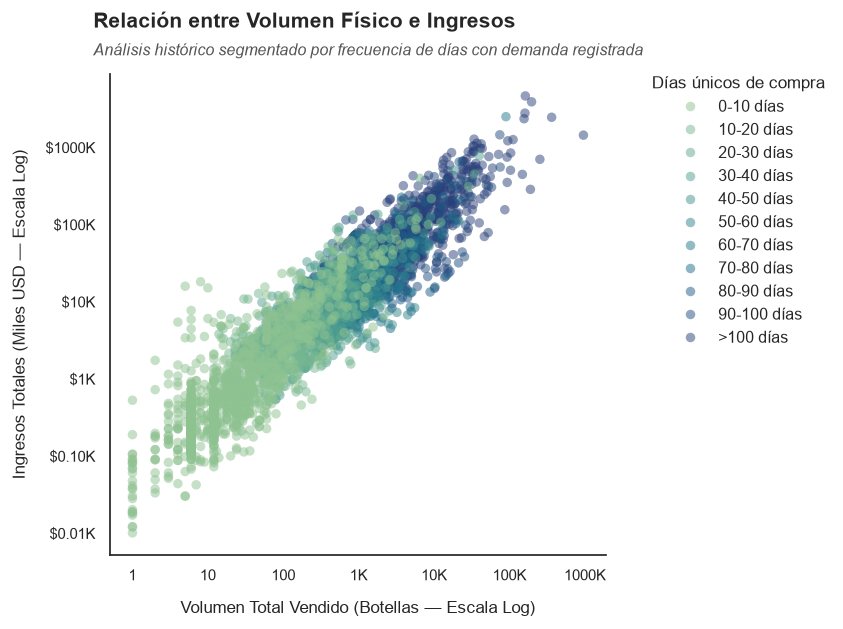

In [7]:
sns.set_theme(context = 'paper', style = 'white')

# Definir el mapa de color continuo
#cmap = sns.dark_palette('#0a428b', n_colors = 11, reverse = True)
cmap = sns.color_palette('crest', n_colors=11)

# Gráfico relplot
g = sns.relplot(
    data = analysis_01,
    x = 'volumen_total',
    y = 'sales_miles',
    hue = 'frecuencia_dias_demanda_cat',
    palette = cmap,
    aspect = 1,
    height = 5,
    alpha = 0.5,
    s = 30,
    linewidth = 0,
    legend = True
)

# Acceso al eje principal del FacetGrid
ax = g.ax

# 1. Aplicar escala logarítmica a ambos ejes
ax.set_xscale('log')
ax.set_yscale('log')

# 2. Formato numérico adaptado a los saltos de escala logarítmica
ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(
        lambda x, _: f'{x/1e3:.0f}K' if x >= 1e3 else f'{int(x)}'
    )
)

ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(
        lambda y, _: f'${y:.0f}K' if y >= 1 else f'${y:.2f}K'
    )
)

# 3. Título principal usando el contenedor de la figura (g.fig)
g.fig.suptitle(
    'Relación entre Volumen Físico e Ingresos',
    fontweight='bold',
    fontsize=12,
    x=0.12,          # Alineado a la izquierda (coincide con el eje)
    y=0.98,          # Posición vertical superior
    ha='left'
)

# 4. Descripción / Subtítulo justo debajo del título principal
g.fig.text(
    0.12,            # Misma coordenada X para mantener la alineación izquierda
    0.91,            # Ligeramente más abajo que el título principal
    'Análisis histórico segmentado por frecuencia de días con demanda registrada',
    fontsize=9,
    style='italic',
    color='#555555', # Gris sutil para diferenciarlo del título
    ha='left'
)

# Ajustar los márgenes superiores de la figura para que no se solapen los títulos
g.fig.subplots_adjust(top=0.88)

ax.set_xlabel('Volumen Total Vendido (Botellas — Escala Log)', labelpad=10)
ax.set_ylabel('Ingresos Totales (Miles USD — Escala Log)', labelpad=10)

sns.move_legend(
    g, 
    loc="upper left", 
    bbox_to_anchor=(0.75, 0.90),  
    frameon=False,               
    facecolor='white',          
    edgecolor='#cccccc',        
    title='Días únicos de compra',
    title_fontsize='10',
    fontsize='9'
)

plt.show()

In [8]:
# Eliminar variables intermedias
del (df_selected_variables, df_eliminated_variables,
    limpiar_texto_own, load_data_own, duplicados_im_desc,
    duplicados_item_no, aux, ax, cmap, g)

<h3 style="color:#05856d">5. Resampling e imputación de 0's</h3>
<hr>

El producto seleccionado para la simulación lleva la categoría **AMERICAN VODKAS (Producto: PRD_001343)**. En 115 días distintos se han generados más de 3 millones de dólares y se han vendido casi 200,000 botellas. Entonces, al aislar este producto, se sumarán todas sus ventas por día (porque en un día puede haber sido comprado por 50 tiendas distintas) y, lo más crítico: se crearán los días en los que no se vendió nada para colocarles demanda = 0.

Si se estudia el resultado, es probable observar algunos días con demanda_diaria = 0. Si no hiciéramos este paso de rellenar los ceros, el agente de AI (Deep Reinforcement Learning) creería que todos los días se vende producto. Al poner los ceros, el agente aprenderá por las malas que si pide mucho inventario en un día malo, se quedará con el producto estancado y se le cobrarán costos de almacenamiento.

In [9]:
df_01.glimpse()

Rows: 964947
Columns: 9
$ bottle_volume_ml  <f64> 750.0, 1750.0, 375.0, 50.0, 1750.0, 375.0, 375.0, 750.0, 750.0, 50.0
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ item_no           <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on       <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ pack              <i64> 12, 6, 24, 10, 6, 24, 24, 12, 12, 12
$ product_code      <str> 'PRD_000917', 'PRD_000180', 'PRD_000176', 'PRD_000156', 'PRD_001524', 'PRD_001520', 'PRD_000487', 'PRD_000935', 'PRD_000906

In [10]:
df_02 = (
    df_01
    .filter(pl.col('product_code') == 'PRD_001343')
    .group_by('ordered_on')
    .agg( pl.sum('sales_bottles').alias('demanda_diaria'),
          pl.sum('sales_dollars').alias('ingresos_diarios'),
          pl.col('pack').drop_nulls().unique() )
)

aux_calendario = pl.DataFrame({
    'ordered_on': pl.date_range(
        start = pl.date(year = 2026, month = 1, day = 1),
        end = df_02['ordered_on'].max(),
        interval = '1d',
        eager = True) })

df_02 = (
    aux_calendario
    .join( other = df_02, on = 'ordered_on', how = 'left', validate = '1:1')
    # Si ese día no hubo ventas, la demanda y el ingreso son 0
    .with_columns([ pl.col('demanda_diaria').fill_null(0),
                    pl.col('ingresos_diarios').fill_null(0) ]) )


df_03 = (
    df_01
    .filter(pl.col('product_code') == 'PRD_001343')
    .select( (pl.sum('sales_dollars') / pl.sum('sales_bottles')).alias('precio_medio'),
             pl.col('pack').drop_nulls().unique() ) )

del aux_calendario

print('-----------------------------------------------------')
print(f'DÍAS TOTALES DE SIMULACIÓN (df_02): {df_02.height}')
df_02.sample(n = 5, seed = 5).show()

print('-----------------------------------------------------')
print('PRECIOS UNITARIOS (df_03)')
df_03.show()


-----------------------------------------------------
DÍAS TOTALES DE SIMULACIÓN (df_02): 150
shape: (5, 4)
┌────────────┬────────────────┬──────────────────┬───────────┐
│ ordered_on ┆ demanda_diaria ┆ ingresos_diarios ┆ pack      │
│ ---        ┆ ---            ┆ ---              ┆ ---       │
│ date       ┆ i64            ┆ f64              ┆ list[i64] │
╞════════════╪════════════════╪══════════════════╪═══════════╡
│ 2026-02-12 ┆ 2231           ┆ 44084.56         ┆ [12]      │
│ 2026-03-31 ┆ 964            ┆ 19048.64         ┆ [12]      │
│ 2026-01-15 ┆ 1997           ┆ 39455.0          ┆ [12]      │
│ 2026-01-09 ┆ 1590           ┆ 31411.0          ┆ [12]      │
│ 2026-03-21 ┆ 0              ┆ 0.0              ┆ null      │
└────────────┴────────────────┴──────────────────┴───────────┘
-----------------------------------------------------
PRECIOS UNITARIOS (df_03)
shape: (1, 2)
┌──────────────┬──────┐
│ precio_medio ┆ pack │
│ ---          ┆ ---  │
│ f64          ┆ i64  │
╞════════

In [11]:
from s_01_functions import eoq_baseline

eoq_baseline = eoq_baseline(
    df_demanda = df_02,
    df_precio = df_03,
    dias_year = 365,
    costo_pedido_S = 50,
    tasa_mantenimiento_i = 0.20 )

print(f'El resultado del lote económico es: {eoq_baseline}')

-------------------------------------------------------
RESULTADOS DEL MODELO BASE (EOQ)
-------------------------------------------------------
Demanda Anual Estimada (D)       : 476,111 botellas
Costo de Mantenimiento Anual (H) : $3.95 por botella
Costo Fijo por Pedido (S)        : $50.00
EOQ Óptimo Teórico               : 3,471 botellas
EOQ Ajustado a Lotes (Acción)    : 290 cajas (packs de 12)
-------------------------------------------------------
El resultado del lote económico es: 290.0


Prueba de humo

In [12]:
# Importar la clase desde tu script modular
from s_01_stock_env import EntornoInventario # Asegúrate de que el nombre del archivo sea el correcto
import polars as pl

# 1. Extraer los parámetros de precio y tamaño de lote
precio_u = df_03['precio_medio'][0]
pack_u = df_03['pack'][0]

if isinstance(pack_u, (list, pl.Series)):
    pack_u = pack_u[0]

# 2. Instanciar el entorno con los datos reales procesados y la ventana histórica
env = EntornoInventario(
    df_demanda = df_02,
    precio_unitario = precio_u,
    tamano_pack = pack_u,
    max_cajas_pedido = 100,
    ventana_historica = 7
)

# 3. Reiniciar el entorno para comenzar el episodio en el Día 0
estado_actual, info = env.reset()
print(f"Estado inicial completo (Inventario + 7 días de memoria):\n{estado_actual}\n")

# 4. Simular los primeros 5 días con un Agente Aleatorio
for dia in range(5):
    # El agente elige una acción al azar usando el action_space que definiste (0 a 100)
    accion_aleatoria = env.action_space.sample()
    
    # El entorno procesa la decisión y avanza un día
    siguiente_estado, recompensa, terminado, truncado, info = env.step(accion_aleatoria)
    
    # Mostrar el reporte del día
    print(f"--- DÍA {dia + 1} ---")
    print(f"📦 Acción del agente : Pidió {accion_aleatoria} cajas")
    print(f"🛒 Ventas reales     : {info['ventas']} botellas")
    print(f"⚠️ Quiebre de stock  : {info['quiebre']} botellas")
    print(f"💰 Recompensa Neta   : ${recompensa:,.2f}")
    # Aquí imprimimos el estado completo para ver cómo se desplaza la demanda
    print(f"🧠 Estado que ve la IA ahora:\n{siguiente_estado}\n")
    
    if terminado:
        print("El episodio ha terminado.")
        break

# Cerrar el entorno por buenas prácticas
env.close()

Estado inicial completo (Inventario + 7 días de memoria):
[0. 0. 0. 0. 0. 0. 0. 0.]

--- DÍA 1 ---
📦 Acción del agente : Pidió 29 cajas
🛒 Ventas reales     : 0 botellas
⚠️ Quiebre de stock  : 0 botellas
💰 Recompensa Neta   : $-50.00
🧠 Estado que ve la IA ahora:
[0. 0. 0. 0. 0. 0. 0. 0.]

--- DÍA 2 ---
📦 Acción del agente : Pidió 25 cajas
🛒 Ventas reales     : 0 botellas
⚠️ Quiebre de stock  : 3679 botellas
💰 Recompensa Neta   : $-7,408.00
🧠 Estado que ve la IA ahora:
[   0.    0.    0.    0.    0.    0.    0. 3679.]

--- DÍA 3 ---
📦 Acción del agente : Pidió 84 cajas
🛒 Ventas reales     : 0 botellas
⚠️ Quiebre de stock  : 0 botellas
💰 Recompensa Neta   : $-50.00
🧠 Estado que ve la IA ahora:
[   0.    0.    0.    0.    0.    0. 3679.    0.]

--- DÍA 4 ---
📦 Acción del agente : Pidió 69 cajas
🛒 Ventas reales     : 68 botellas
⚠️ Quiebre de stock  : 0 botellas
💰 Recompensa Neta   : $1,163.21
🧠 Estado que ve la IA ahora:
[ 280.    0.    0.    0.    0. 3679.    0.   68.]

--- DÍA 5 ---
📦 Ac

In [13]:
# Importar la librería de Inteligencia Artificial
from stable_baselines3 import PPO

# Importar tu entorno personalizado
from s_01_stock_env import EntornoInventario

# 1. Extraer los parámetros de precio y tamaño de lote desde los DataFrames
precio_u = df_03['precio_medio'][0]
pack_u = df_03['pack'][0]

if isinstance(pack_u, (list, pl.Series)):
    pack_u = pack_u[0]

# 2. Instanciar el entorno de entrenamiento
env = EntornoInventario(
    df_demanda = df_02,
    precio_unitario = precio_u,
    tamano_pack = pack_u,
    max_cajas_pedido = 100,
    ventana_historica = 7
)

# 3. Crear el cerebro del Agente (Red Neuronal Optimizada)
print('🧠 Instanciando la Red Neuronal PPO (Alta Exploración)...')
modelo_ppo = PPO(
    'MlpPolicy', 
    env, 
    verbose=1, 
    seed=42, 
    ent_coef=0.01, 
    learning_rate=0.0002
)

# 4. Iniciar el Entrenamiento Intensivo
print('🚀 Iniciando el entrenamiento. Esto tomará unos minutos...')
modelo_ppo.learn(total_timesteps=1000000)

# 5. Guardar el modelo entrenado
modelo_ppo.save('agente_inventario_ppo_optimizado')
print('✅ ¡Entrenamiento intensivo finalizado y modelo guardado!')

env.close()

🧠 Instanciando la Red Neuronal PPO (Alta Exploración)...
Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
🚀 Iniciando el entrenamiento. Esto tomará unos minutos...
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 150      |
|    ep_rew_mean     | 1.49e+06 |
| time/              |          |
|    fps             | 2683     |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 2048     |
---------------------------------
-------------------------------------------
| rollout/                |               |
|    ep_len_mean          | 150           |
|    ep_rew_mean          | 1.49e+06      |
| time/                   |               |
|    fps                  | 1608          |
|    iterations           | 2             |
|    time_elapsed         | 2             |
|    total_timesteps      | 4096          |
| train/                  |               |
|    approx

In [ ]:
from stable_baselines3 import PPO

# 1. Cargar el NUEVO modelo entrenado optimizado
print("Cargando el Agente Inteligente Optimizado...")
agente_inteligente_v2 = PPO.load('agente_inventario_ppo_optimizado')

# 2. Reiniciar el entorno para una prueba limpia
estado, info = env.reset()

historial_recompensas_v2 = []
historial_quiebres_v2 = []
historial_acciones_v2 = []

terminado = False
truncado = False

print("\n🚀 Iniciando simulación de evaluación...\n")

# 3. Bucle de evaluación determinista
while not (terminado or truncado):
    # Pedimos al nuevo modelo que tome la mejor decisión posible sin azar
    accion, _ = agente_inteligente_v2.predict(estado, deterministic=True)
    accion_entera = int(accion)
    
    # El entorno procesa la decisión
    estado, recompensa, terminado, truncado, info = env.step(accion_entera)
    
    # Guardamos los resultados
    historial_recompensas_v2.append(recompensa)
    historial_quiebres_v2.append(info['quiebre'])
    historial_acciones_v2.append(accion_entera)

# 4. Consolidar resultados del PPO v2.0
rentabilidad_v2 = sum(historial_recompensas_v2)
quiebres_v2 = sum(historial_quiebres_v2)
cajas_v2 = sum(historial_acciones_v2)

# 5. Cargar los datos del EOQ que calculaste en la prueba anterior
rentabilidad_eoq = 3143961.98
cajas_eoq = 14450
quiebres_eoq = 32666

# 6. Generar la tabla comparativa definitiva
tabla_final = pd.DataFrame({
    'Métrica Logística': [
        'Rentabilidad Total (USD)', 
        'Total Cajas Pedidas', 
        'Quiebres de Stock (Botellas)'
    ],
    'Baseline EOQ': [
        f"${rentabilidad_eoq:,.2f}", 
        f"{cajas_eoq:,.0f}", 
        f"{quiebres_eoq:,.0f}"
    ],
    'Agente PPO Optimizado': [
        f"${rentabilidad_v2:,.2f}", 
        f"{cajas_v2:,.0f}", 
        f"{quiebres_v2:,.0f}"
    ]
})

print("📊 COMPARATIVA DEFINITIVA: EOQ vs PPO Optimizado")
tabla_final

Cargando el Agente Inteligente Optimizado...

🚀 Iniciando simulación de evaluación...

📊 COMPARATIVA DEFINITIVA: EOQ vs PPO Optimizado


,Métrica Logística,Baseline EOQ,Agente PPO Optimizado
0,Rentabilidad Total (USD),"$3,143,961.98","$2,718,823.16"
1,Total Cajas Pedidas,"14,450","14,768"
2,Quiebres de Stock (Botellas),"32,666","37,850"


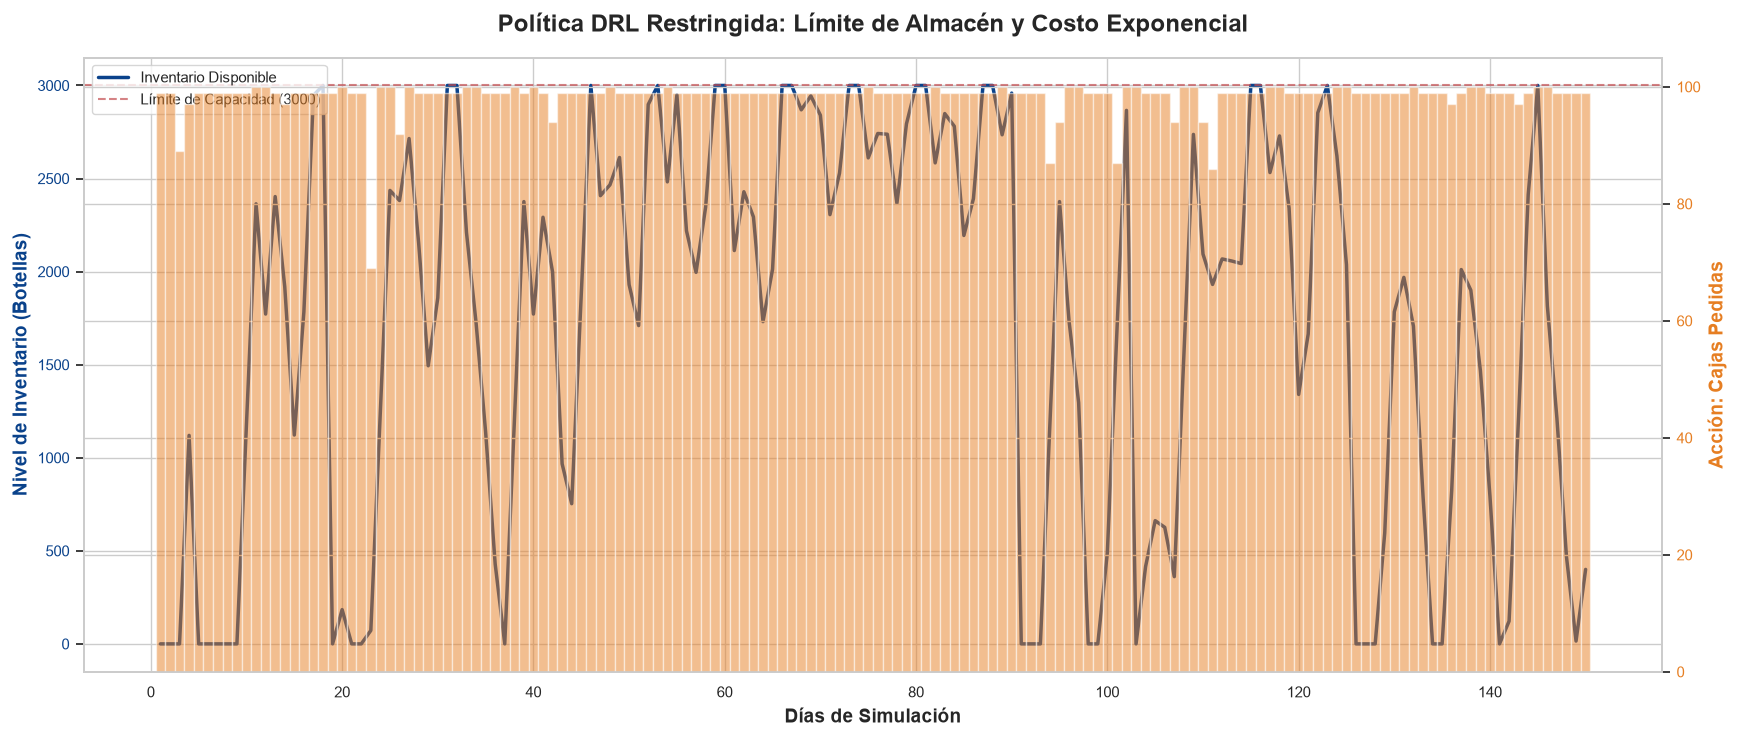

In [21]:
# 1. Crear el DataFrame con los datos de la versión ESTRICTA
df_resultados_estrictos = pd.DataFrame({
    'Día': range(1, len(historial_inventario_v2) + 1),
    'Inventario': historial_inventario_v2,
    'Cajas_Pedidas': historial_acciones_v2,
    'Quiebres': historial_quiebres_v2
})

# 2. Configurar el estilo del gráfico
sns.set_theme(context='paper', style='whitegrid')
fig, ax1 = plt.subplots(figsize=(14, 6))

# 3. Graficar el Nivel de Inventario (Línea Azul)
color_inv = '#0a428b'
ax1.set_xlabel('Días de Simulación', fontweight='bold', fontsize=11)
ax1.set_ylabel('Nivel de Inventario (Botellas)', color=color_inv, fontweight='bold', fontsize=11)
ax1.plot(df_resultados_estrictos['Día'], df_resultados_estrictos['Inventario'], color=color_inv, linewidth=2, label='Inventario Disponible')
ax1.tick_params(axis='y', labelcolor=color_inv)

# Añadimos una línea roja punteada para marcar el límite del almacén
ax1.axhline(y=3000, color='r', linestyle='--', alpha=0.7, label='Límite de Capacidad (3000)')
ax1.legend(loc='upper left')

# 4. Crear un segundo eje Y para graficar los pedidos del Agente (Barras Naranjas)
ax2 = ax1.twinx()  
color_acc = '#e67e22'
ax2.set_ylabel('Acción: Cajas Pedidas', color=color_acc, fontweight='bold', fontsize=11)
ax2.bar(df_resultados_estrictos['Día'], df_resultados_estrictos['Cajas_Pedidas'], color=color_acc, alpha=0.5, width=1.0, label='Cajas Pedidas')
ax2.tick_params(axis='y', labelcolor=color_acc)

# 5. Estética final
plt.title('Política DRL Restringida: Límite de Almacén y Costo Exponencial', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout() 
plt.show()